# From the Web to a Classifier

We build a text classification dataset from scratch, and evaluate a model on it. The question:

> *Given the first paragraph of a Wikipedia biography, what is the person mainly known for?*

The labels are nine domains: visual arts, literature, music, film and stage, science, politics, religion,
sport, and other. The people are all **from Tuscany**.

The notebook follows the whole pipeline:

1. **collect** the texts: scraping HTML pages, then an API;
2. **inspect** and clean them;
3. **label** them automatically from Wikipedia's categories (**silver** labels);
4. compare those labels with labels written by a person (**gold** labels), and measure the **agreement**;
5. **train** a classifier on the silver labels and **evaluate** it on the gold ones.

All the texts come from the English Wikipedia and are licensed under CC BY-SA 4.0.

In [170]:
# Run once if you are not using the course environment.
# %pip install -q requests beautifulsoup4 numpy pandas scikit-learn matplotlib

---
## Collecting the data

### Asking for permission: `robots.txt`

Every polite scraper starts by reading the site's `robots.txt`, which says which paths crawlers may visit.
We also send a **User-Agent** that says who we are: Wikipedia asks for one, and refuses requests without it.

In [171]:
import time
import requests
from urllib import robotparser

USER_AGENT = "TextAnalytics-UniPi-course (student exercise)"
session = requests.Session()
session.headers["User-Agent"] = USER_AGENT

robots = robotparser.RobotFileParser()
robots.parse(session.get("https://en.wikipedia.org/robots.txt").text.splitlines())

for url in ["https://en.wikipedia.org/wiki/Galileo_Galilei",
            "https://en.wikipedia.org/wiki/Special:Random",
            "https://en.wikipedia.org/w/api.php"]:
    print(f"{robots.can_fetch(USER_AGENT, url)!s:5}  {url}")

True   https://en.wikipedia.org/wiki/Galileo_Galilei
False  https://en.wikipedia.org/wiki/Special:Random
False  https://en.wikipedia.org/w/api.php


Articles can be crawled, special pages cannot. The API (`/w/api.php`) is also closed to **crawlers**, but it is
meant for programs that request specific data, and has its own usage rules: we will use it below, for the bulk
of the corpus.

> `robotparser` can download the file itself (`robots.read()`), but it does so without our User-Agent,
> Wikipedia answers *403 Forbidden*, and the parser then concludes that **everything** is forbidden. This is why
> we download the file with our own session and pass its lines to `parse`.

### Scraping one page

A page is a tree of HTML elements. In a Wikipedia article, the text is inside the element with
`id="mw-content-text"`, and the introduction is its first `<section>`.

In [172]:
from bs4 import BeautifulSoup

def get_soup(url):
    # Fetch the page, timing out after 20 seconds if the server does not respond.
    response = session.get(url, timeout=20)
    response.raise_for_status()  # Raise an error for HTTP failures, such as 404 or 403.
    return BeautifulSoup(response.text, "html.parser")  # Parse the HTML into a searchable structure.

# Download and parse Galileo Galilei's Wikipedia page.
soup = get_soup("https://en.wikipedia.org/wiki/Galileo_Galilei")

# Select the main article's content area.
lead = soup.select_one("#mw-content-text > .mw-parser-output > section")

# Find the first paragraph in that section that contains non-whitespace text.
first = next(p for p in lead.find_all("p") if p.get_text(strip=True))

# Print the paragraph's text without its HTML tags.
print(first.get_text())

Galileo di Vincenzo Bonaiuti de' Galilei (15 February 1564 – 8 January 1642), commonly referred to as Galileo Galilei[a] or mononymously as Galileo, was an Italian[b] astronomer, physicist, engineer and  polymath. He was born in Pisa, then part of the Duchy of Florence.[8] Galileo has been called the father of observational astronomy,[9] classical physics,[10] the scientific method,[11] and modern science.[12]


The text contains **citation markers** (`[a]`, `[b]`): they are `<sup class="reference">` elements, and we
remove them from the tree before extracting the text. We also collapse the whitespace.

In [173]:
def first_paragraph(soup):
    # Select the article's main content area.
    lead = soup.select_one("#mw-content-text > .mw-parser-output > section")

    # Remove citation markers from the section.
    for sup in lead.select("sup.reference"):
        sup.decompose()  # Delete the element from the parsed HTML tree.

    # Find the first paragraph that contains non-whitespace text.
    first = next(p for p in lead.find_all("p") if p.get_text(strip=True))

    # Extract the paragraph's text and normalize all whitespace to single spaces.
    return " ".join(first.get_text().split())

def categories(soup):
    # Get the text of each category link at the bottom of the page.
    return [a.get_text() for a in soup.select("#mw-normal-catlinks li a")]

print(first_paragraph(soup))
print()
print(categories(soup)[:8])

Galileo di Vincenzo Bonaiuti de' Galilei (15 February 1564 – 8 January 1642), commonly referred to as Galileo Galilei or mononymously as Galileo, was an Italian astronomer, physicist, engineer and polymath. He was born in Pisa, then part of the Duchy of Florence. Galileo has been called the father of observational astronomy, classical physics, the scientific method, and modern science.

['Galileo Galilei', '1564 births', '1642 deaths', '16th-century Italian astronomers', '16th-century Italian inventors', '16th-century Italian mathematicians', '16th-century Italian male writers', '16th-century Roman Catholics']


The **categories** at the bottom of the page are written by Wikipedia's editors. They are not part of the text we
will classify, but they say a lot about the person: we will use them to label the data automatically.

### Following links: a category page

A category page lists its members, and its subcategories. Scraping is mostly this: find the pages that list
the URLs we want, then visit each URL, **pausing** between requests.

In [174]:
from urllib.parse import urljoin

category_url = "https://en.wikipedia.org/wiki/Category:People_from_Pisa"
cat_soup = get_soup(category_url)

subcategories = [a.get_text() for a in cat_soup.select("#mw-subcategories li a") if a.get_text()]
member_urls = [urljoin(category_url, a["href"]) for a in cat_soup.select("#mw-pages li a")]

print(len(member_urls), "pages, and these subcategories:", subcategories)

88 pages, and these subcategories: ['People from Pisa by occupation', 'Families of Pisa', "Sant'Anna School of Advanced Studies alumni", 'Scuola Normale Superiore alumni', 'University of Pisa alumni']


In [ ]:
import numpy as np
import pandas as pd

scraped = []
for url in member_urls[:5]:  # only five: every page is a request
    page = get_soup(url)
    scraped.append({"title": page.h1.get_text(), "text": first_paragraph(page), "categories": categories(page)})
    time.sleep(1)   # one request per second

pd.DataFrame(scraped)

,title,text,categories
0,Luisa Adorno,"Luisa Adorno, pseudonym of Mila Curradi (2 Aug...","[1921 births, 2021 deaths, 20th-century Italia..."
1,Massimiliano Angori,Massimiliano Angori (born 17 July 1967) is an ...,"[1967 births, Living people, Mayors of places ..."
2,Anselm of Capraia,Anselm of Capraia was a Pisan count. His polit...,"[1287 deaths, People from Pisa, Judges of Arbo..."
3,Emanuele Appiani,Emanuele Appiani (c. 1380 – 15 February 1457) ...,"[1380s births, 1457 deaths, Appiani family, Pe..."
4,Gherardo Appiani,Gherardo Appiani (c. 1370 – May 1405) was the ...,"[1370s births, 1405 deaths, Appiani family, Pe..."


### The same with the API

Most people from Pisa are not in this page, but in its subcategories (*People from Pisa by occupation*, then
*Painters from Pisa*, *Footballers from Pisa*, ...). Downloading thousands of full HTML pages, about 300 kB each,
to keep one paragraph would be wasteful. For bulk downloads, Wikipedia asks to use its **API**, which returns
just the fields we ask for, for up to 20 pages per request.

In [ ]:
API = "https://en.wikipedia.org/w/api.php"

def api_pages(titles):
    # Fetch the introduction and visible categories for up to 20 Wikipedia page titles.
    params = {
        "action": "query",   # Ask the MediaWiki API to query pages.
        "format": "json",  # Return the result as JSON.
        "titles": "|".join(titles),  # Request several titles in one API call.
        "redirects": 1,  # Follow redirects to the target pages.
        "prop": "extracts|categories",  # Include page text extracts and categories.
        "exintro": 1,  # Return only the introductory section.
        "explaintext": 1,  # Return the extract as plain text.
        "exlimit": 20,  # Allow extracts for up to 20 pages.
        "clshow": "!hidden",  # Exclude hidden categories.
        "cllimit": "max", # Return as many categories as allowed per response.
    }

    pages, cont = {}, {}

    while True:  # Category results may be split across multiple API responses.
        # Make the API request, adding continuation parameters if this is a follow-up request.
        answer = session.get(API, params={**params, **cont}).json()

        # Process each page returned by the API.
        for p in answer["query"]["pages"].values():
            # Create a record for the page the first time it appears.
            page = pages.setdefault(
                p["title"],
                {"title": p["title"], "text": "", "categories": []}
            )

            # Save the first line of the introduction, if one was returned.
            if p.get("extract"):
                page["text"] = p["extract"].strip().split("\n")[0]

            # Add category names, removing the "Category:" prefix.
            page["categories"] += [
                c["title"].removeprefix("Category:")
                for c in p.get("categories", [])
            ]

        # Pause briefly between API requests.
        time.sleep(0.5)

        # If there are no more results to fetch, return the collected page records.
        if "continue" not in answer:
            return list(pages.values())

        # Save the continuation values for the next API request.
        cont = answer["continue"]

# Fetch data for three pages and display it as a pandas DataFrame.
pd.DataFrame(api_pages(["Galileo Galilei", "Andrea Pisano", "Giorgio Chiellini"]))

,title,text,categories
0,Andrea Pisano,Andrea Pisano (Pontedera 1290 – 1348 Orvieto) ...,"[1290 births, 1340s deaths, 14th-century Itali..."
1,Galileo Galilei,Galileo di Vincenzo Bonaiuti de' Galilei (15 F...,"[1564 births, 1642 deaths, 16th-century Italia..."
2,Giorgio Chiellini,Giorgio Chiellini (Italian pronunciation: [ˈd...,"[1984 births, 2009 FIFA Confederations Cup pla..."


The corpus of this notebook was built this way: starting from the categories *People from Florence*, *Pisa*,
*Siena*, *Lucca*, *Livorno*, *Arezzo*, *Pistoia*, *Prato*, *Grosseto* and *Carrara*, we followed their
subcategories (skipping alumni, families and fictional people), then asked the API for every page found.
About 400 requests in all. Of each page's categories we kept only those that the labeling rules below use: the labels
are the same, and tags about religion, origin or sexual orientation, which the task does not need, are gone.
This is **data minimization**. The result is saved in `data/people.jsonl`: we load it, instead of downloading it
again.

In [178]:
people = pd.read_json("data/people.jsonl", lines=True)
print(len(people), "pages")
people.head()

2567 pages


,title,url,city,text,categories
0,AG Fronzoni,https://en.wikipedia.org/wiki/AG_Fronzoni,Pistoia,Angiolo Giuseppe Fronzoni (5 March 1923 – 8 Fe...,[Italian graphic designers]
1,Abigaille Bruschi-Chiatti,https://en.wikipedia.org/wiki/Abigaille_Brusch...,Arezzo,Abigaille Bruschi-Chiatti (c. 1855 – after 188...,"[19th-century Italian women opera singers, Ita..."
2,Achille Piccini,https://en.wikipedia.org/wiki/Achille_Piccini,Carrara,Achille Piccini (Italian pronunciation: [aˈkil...,"[20th-century Italian sportsmen, ACF Fiorentin..."
3,Ada Mangilli,https://en.wikipedia.org/wiki/Ada_Mangilli,Florence,"Ada Mangilli (Cento, 23 September 1863 - Flore...","[19th-century Italian painters, 19th-century I..."
4,Adalberto Minucci,https://en.wikipedia.org/wiki/Adalberto_Minucci,Grosseto,Adalberto Minucci (4 March 1932 – 20 September...,"[Democratic Party of the Left politicians, Dep..."


---
## Inspecting the data

Before labeling anything, we look at what we collected.

In [179]:
people["words"] = people["text"].str.split().str.len()

print(people["city"].value_counts().to_string())
print()
print(people["words"].describe().round(1).to_string())

city
Florence    1155
Siena        260
Pisa         247
Livorno      219
Lucca        193
Arezzo       127
Pistoia      101
Prato         96
Grosseto      95
Carrara       74

count    2567.0
mean       36.6
std        28.0
min         4.0
25%        18.0
50%        27.0
75%        47.0
max       459.0


Florence alone accounts for almost half of the people: a corpus built from city categories inherits the size of
the cities, and of their Wikipedia coverage. The paragraphs are short (half of them under 30 words), with a
long tail. The shortest and the longest:

In [180]:
for _, row in people.sort_values("words").iloc[[0, 1, 2, -1]].iterrows():
    print(f"{row.words:4d} words | {row.title}: {row.text[:200]}")

   4 words | Bandino Gualfreducci: Bandino Gualfreducci (1565 –
   6 words | Adam Alexi-Malle: Adam Alexi-Malle is an Italian actor.
   7 words | Antonio Costa (painter): Antonio Costa (1847–1915) was an Italian painter.
 459 words | Giancarlo Tognoni: Giancarlo Tognoni (22 June 1932 - 13 December 2020).Giancarlo Tognoni was an Italian painter, engraver and sculptor.  He was born in Pisa, but continued his studies in Florence, where he attended the 


The shortest paragraph was cut off by the extraction, and the longest is a page whose paragraphs are not
separated, so the "first paragraph" is the whole introduction. Both are cleaning problems. They are rare, so we
leave them, but a real project would check them.

In [183]:
print("duplicated titles:", people["title"].duplicated().sum())
print("duplicated texts: ", people["text"].duplicated().sum())

people.sample(5, random_state=0)[["title", "text"]]

duplicated titles: 0
duplicated texts:  0


,title,text
1602,Lorenzo Doveri,Lorenzo Doveri (10 August 1799 – 6 October 186...
1960,Nico Vivarelli,Nico Vivarelli (born 30 August 1986) is a Gran...
1174,Giovanni Battista Cipriani,Giovanni Battista Cipriani (1727 – 14 Decembe...
634,Desiderio da Settignano,"Desiderio da Settignano, real name Desiderio d..."
1661,Lucifer of Siena,"Lucifer of Siena (3rd century – 4th century), ..."


---
## Understanding the corpus without labels

Before deciding how to label the data, it helps to see what is in it. Two tools from unsupervised learning
give a first map of the corpus: **clustering** groups similar paragraphs, **topic models** find groups of
words that occur together. No label is used here.

**First, the test set goes aside.** The 200 paragraphs that will be annotated by hand are our test set, and
we know which ones they are before exploring. Exploring is not neutral: what we see in the data shapes our
decisions (which words to remove, which classes look hard), and anything we fit, from a vocabulary to the
clusters, is learned from the data. So we explore the other paragraphs only. We read just the **titles** of the
test paragraphs, not their labels.

### Clustering

The training paragraphs become TF-IDF vectors (without numbers, which are mostly dates, and without the words in more than
half of the paragraphs, such as *Italian*), reduced to 50 dimensions with truncated SVD and normalized to length 1.

In [185]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.cluster import KMeans

# Load the titles reserved for evaluation.
test_titles = set(pd.read_csv("data/gold_annotations.csv", encoding="utf-8-sig")["title"])  # titles only

# Keep people whose titles are not in the reserved evaluation set.
explore = people[~people.title.isin(test_titles)].copy()
print(len(explore), "paragraphs to explore,", len(test_titles), "set aside")

WORDS_ONLY = r"(?u)\b[a-zA-Z][a-zA-Z]+\b"  # tokens of letters only: no years

# Create TF-IDF features, ignoring rare terms, very common terms, and English stop words.
tfidf_all = TfidfVectorizer(min_df=3, max_df=0.5, stop_words="english", token_pattern=WORDS_ONLY)
X_explore = tfidf_all.fit_transform(explore["text"])

# Store the vocabulary corresponding to the TF-IDF columns.
terms = tfidf_all.get_feature_names_out()

# Reduce the feature dimensions to 50, then normalize each paragraph vector.
Z = Normalizer().fit_transform(TruncatedSVD(n_components=50, random_state=0).fit_transform(X_explore))
print("paragraphs x terms:", X_explore.shape, "-> reduced:", Z.shape)

2367 paragraphs to explore, 200 set aside
paragraphs x terms: (2367, 2213) -> reduced: (2367, 50)


How many clusters? The **inertia**, the k-means loss, always decreases as $K$ grows, so it cannot be minimized:
we compute it by hand for several values of $K$ and look for an **elbow**.

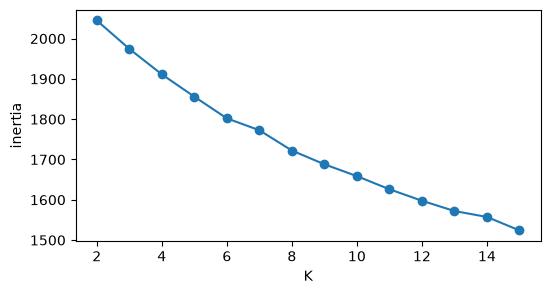

In [186]:
ks = list(range(2, 16))
inertia = [KMeans(n_clusters=k, n_init=5, random_state=0).fit(Z).inertia_ for k in ks]

plt.figure(figsize=(6, 3))
plt.plot(ks, inertia, marker="o")
plt.xlabel("K"); plt.ylabel("inertia")
plt.show()

The **silhouette**, instead, can be maximized, so the choice of $K$ can be automated like any other
hyperparameter. `GridSearchCV` works without labels too: it fits k-means on the training folds and calls our
**scorer** on the held-out fold, which returns the silhouette of the held-out paragraphs. (Its default score,
`KMeans.score`, is minus the inertia, and would always choose the largest $K$.)

In [187]:
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV, KFold

def silhouette_scorer(estimator, X, y=None):
    return silhouette_score(X, estimator.predict(X))   # clusters learned on the other folds

k_search = GridSearchCV(
    KMeans(
        n_init=5, random_state=0
        ), 
    {"n_clusters": ks},
    scoring=silhouette_scorer, 
    cv=KFold(3, shuffle=True, random_state=0)
).fit(Z)

print("best K by silhouette:", k_search.best_params_["n_clusters"])
pd.Series(k_search.cv_results_["mean_test_score"], index=ks, name="silhouette").round(3).to_frame().T

best K by silhouette: 13


,2,3,4,5,6,7,8,9,10,11,12,13,14,15
silhouette,0.044,0.051,0.062,0.07,0.075,0.082,0.083,0.088,0.091,0.092,0.098,0.102,0.1,0.097


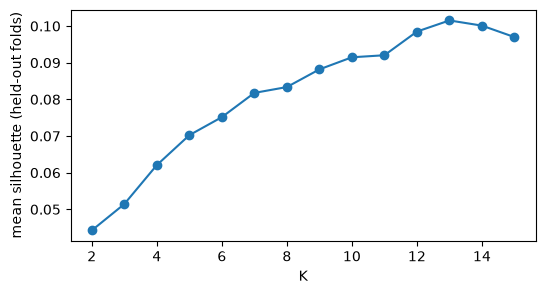

In [188]:
plt.figure(figsize=(6, 3))
plt.plot(ks, k_search.cv_results_["mean_test_score"], marker="o")
plt.xlabel("K"); plt.ylabel("mean silhouette (held-out folds)")
plt.show()

The silhouette grows slowly with $K$ and stays low, around 0.1, and the elbow of the inertia is gentle: short
paragraphs that share most of their words form overlapping groups, with no clear number of clusters. The two curves
narrow the choice; reading the clusters decides.

In [189]:
K = 9   # as many as our domains, to compare them later
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
explore["cluster"] = km.labels_

for j in range(K):
    members = (km.labels_ == j)
    centroid = np.asarray(X_explore[members].mean(axis=0)).ravel()
    print(f"cluster {j} ({members.sum():4d}): " + ", ".join(terms[np.argsort(centroid)[-8:][::-1]]))

cluster 0 ( 231): florence, born, painter, italy, march, known, writer, july
cluster 1 ( 221): politician, served, mayor, member, born, president, party, province
cluster 2 ( 230): professional, footballer, born, player, plays, serie, played, club
cluster 3 ( 168): catholic, bishop, cardinal, roman, prelate, archbishop, served, church
cluster 4 ( 132): olympics, summer, competed, event, won, medal, fencer, team
cluster 5 ( 317): painter, active, mainly, baroque, period, florence, style, giovanni
cluster 6 ( 180): di, renaissance, painter, sculptor, giovanni, florence, active, known
cluster 7 ( 772): architect, born, known, october, september, april, november, march
cluster 8 ( 116): actor, film, director, screenwriter, born, television, actress, stage


Most clusters are recognizable domains: politicians (1), footballers (2), bishops (3), Olympic athletes (4),
actors and directors (8). Painters fill three clusters, split by period and place: Baroque painters (5),
Renaissance painters and sculptors (6), and a Florentine cluster mixing painters and writers (0).

Cluster 7, the largest, is held together by *born* and the **month names** of the birth dates: a cluster of
paragraph *style*, not of domain. Removing the years was not enough. Music and science have no cluster of their
own.

### Looking at the clusters

The top terms of each cluster, with their weight in the mean TF-IDF vector of the cluster:

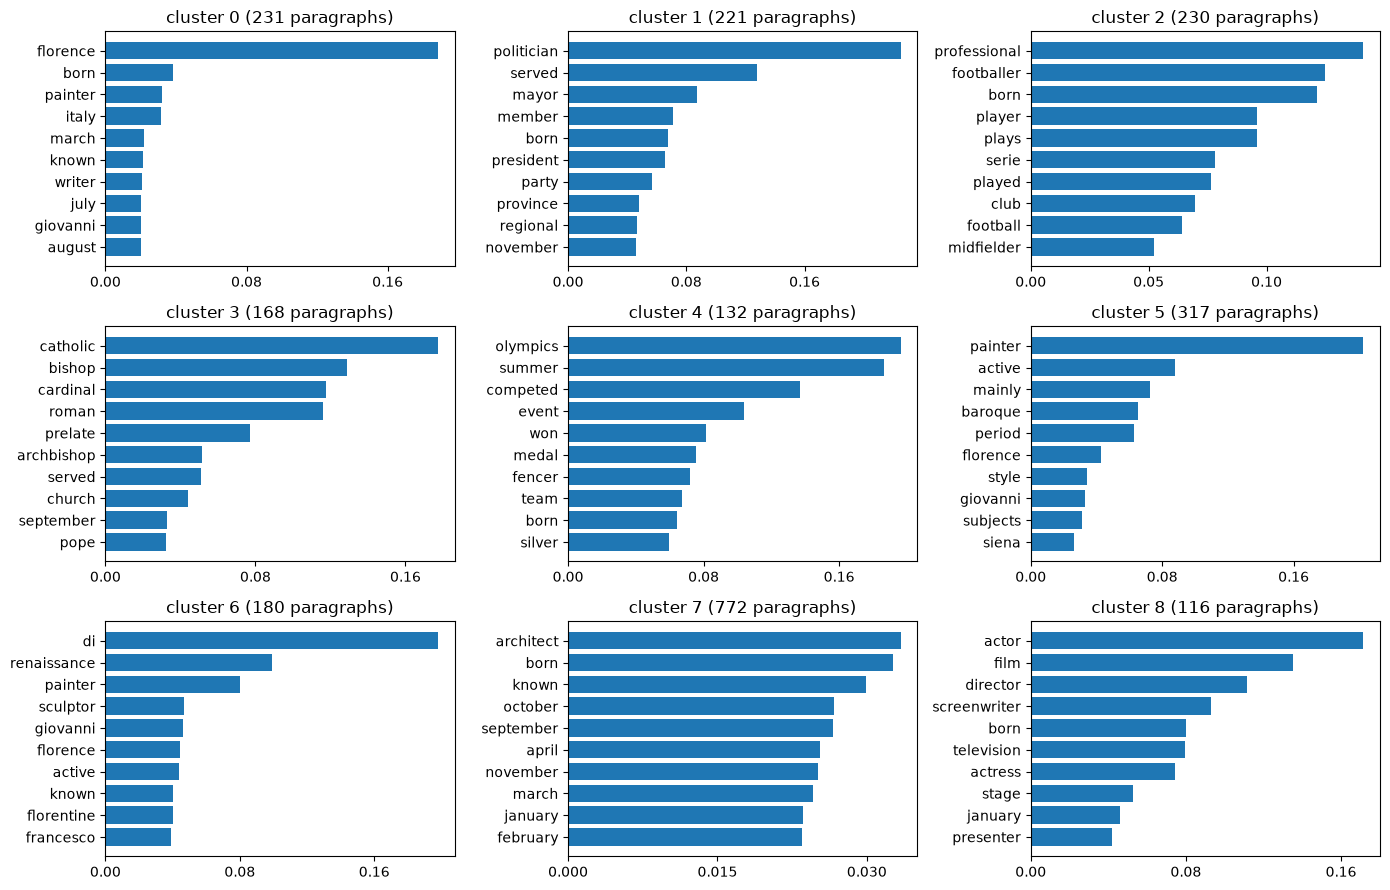

In [190]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for j, ax in enumerate(axes.ravel()):
    centroid = np.asarray(X_explore[km.labels_ == j].mean(axis=0)).ravel()
    top = np.argsort(centroid)[-10:]
    ax.barh(terms[top], centroid[top])
    ax.set_title(f"cluster {j} ({(km.labels_ == j).sum()} paragraphs)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
plt.tight_layout()
plt.show()

The silhouette of every paragraph, cluster by cluster. Paragraphs below 0 are closer to another cluster than to
their own.

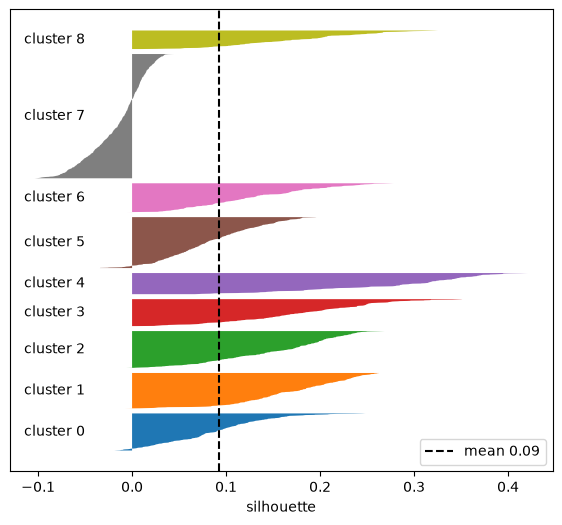

,0,1,2,3,4,5,6,7,8
mean silhouette,0.09,0.17,0.15,0.18,0.28,0.08,0.13,-0.02,0.17
share below 0,0.05,0.00,0.00,0.00,0.00,0.05,0.01,0.63,0.00


In [191]:
from sklearn.metrics import silhouette_samples

sil = silhouette_samples(Z, km.labels_)

plt.figure(figsize=(7, 6))
bottom = 0
for j in range(K):
    values = np.sort(sil[km.labels_ == j])
    plt.fill_betweenx(np.arange(bottom, bottom + len(values)), 0, values)
    plt.text(-0.05, bottom + len(values) / 2, f"cluster {j}", ha="right", va="center")
    bottom += len(values) + 30
plt.axvline(sil.mean(), color="black", linestyle="--", label=f"mean {sil.mean():.2f}")
plt.xlabel("silhouette"); plt.yticks([]); plt.legend()
plt.show()

pd.DataFrame({"mean silhouette": pd.Series(sil).groupby(km.labels_).mean(),
              "share below 0": pd.Series(sil < 0).groupby(km.labels_).mean()}).round(2).T

Cluster 7, the largest, is not a real group: its mean silhouette is below 0, and 63% of its paragraphs are closer
to another cluster than to their own. It is the cluster held together by the dates. The Olympic athletes (4) are
the most compact cluster (0.28); all the others are positive but low, as expected from overlapping groups.

To draw the paragraphs we need two dimensions. **PCA** keeps the two directions with the largest variance;
**t-SNE** places close together the paragraphs that are close in the 50 dimensions, at the cost of distorting the
large distances. Hover on a point to read its paragraph.

In [19]:
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

points = pd.DataFrame({"cluster": [f"cluster {j}" for j in km.labels_],
                       "title": explore["title"].to_numpy(),
                       "paragraph": explore["text"].str[:150].to_numpy()})
order = {"cluster": [f"cluster {j}" for j in range(K)]}

pca_2d = PCA(n_components=2, random_state=0).fit_transform(Z)
points["pca 1"], points["pca 2"] = pca_2d[:, 0], pca_2d[:, 1]
fig = px.scatter(points, x="pca 1", y="pca 2", color="cluster", hover_data=["title", "paragraph"],
                 category_orders=order, opacity=0.7, title="PCA", width=850, height=550)
fig.update_traces(marker_size=4)
fig.show()

In [20]:
tsne_2d = TSNE(n_components=2, init="pca", random_state=0).fit_transform(Z)
points["tsne 1"], points["tsne 2"] = tsne_2d[:, 0], tsne_2d[:, 1]
fig = px.scatter(points, x="tsne 1", y="tsne 2", color="cluster", hover_data=["title", "paragraph"],
                 category_orders=order, opacity=0.7, title="t-SNE", width=850, height=550)
fig.update_traces(marker_size=4)
fig.show()

PCA keeps only two of the 50 directions, so the clusters overlap on the plot even where they are separated in 50
dimensions. On the t-SNE map, look for the compact groups of the clusters with a clear vocabulary (bishops,
footballers, actors), and for cluster 7: with a negative silhouette, its paragraphs should be scattered among the
others.

### Topics

LDA describes each paragraph as a **mixture** of topics, and each topic as a distribution over words. It works on
word **counts**. To choose the number of topics we fit LDA on 80% of the paragraphs and compare:

- the **perplexity** on the paragraphs it was fit on, and on the 20% it never saw;
- the **coherence** of the topics: the average normalized PMI (NPMI) between the top 10 words of each topic,
  estimated from how often they occur in the same paragraphs. It ranges from $-1$ to $1$; higher is better.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split

count_vect = CountVectorizer(min_df=3, max_df=0.5, stop_words="english", token_pattern=WORDS_ONLY)
docs_fit, docs_held = train_test_split(explore["text"], test_size=0.2, random_state=0)

C_fit = count_vect.fit_transform(docs_fit)
C_held = count_vect.transform(docs_held)

words = count_vect.get_feature_names_out()

# Build a binary document-term matrix: 1 means a word appears in a document.
B = (C_fit > 0).astype(np.float32)
n_docs = B.shape[0]

# Calculate the fraction of documents containing each word.
p_word = np.asarray(B.sum(axis=0)).ravel() / n_docs

# Calculate the fraction of documents containing each pair of words.
p_pair = (B.T @ B).toarray() / n_docs

def coherence(lda, top=10):
    # Compute the average NPMI coherence for each topic's top words.
    values = []

    # Process each topic's learned word weights.
    for row in lda.components_:
        # Find the column indices of the topic's top-weighted words.
        w = np.argsort(row)[-top:]

        # Calculate NPMI for every pair of top words.
        for a in range(top):
            for b in range(a + 1, top):
                pij = p_pair[w[a], w[b]]
                values.append(-1.0 if pij == 0 else
                              np.log(pij / (p_word[w[a]] * p_word[w[b]])) / -np.log(pij))

    return np.mean(values)

# Fit LDA models with different numbers of topics and collect evaluation scores.
rows = []
for k in [3, 6, 9, 12, 20]:
    lda = LatentDirichletAllocation(n_components=k, learning_method="batch", max_iter=20, random_state=0).fit(C_fit)
    rows.append(
        {
            "topics": k, 
            "train perplexity": lda.perplexity(C_fit),
            "held-out perplexity": lda.perplexity(C_held), 
            "coherence (NPMI)": coherence(lda)
        }
    )

# Display the results rounded to three decimal places.
pd.DataFrame(rows).round(3)

,topics,train perplexity,held-out perplexity,coherence (NPMI)
0,3,789.050,1545.619,0.038
1,6,821.328,2535.078,0.074
2,9,901.570,4152.033,0.020
3,12,936.821,5926.960,0.093
4,20,1015.278,13108.174,0.026


The held-out perplexity grows quickly with the number of topics, and the gap with the training perplexity widens,
from 2 times at 3 topics to 13 times at 20: more topics fit the particulars of the training paragraphs. The
coherence is low and unstable, jumping from one number of topics to the next, and highest at 12. Perplexity and
coherence disagree, as they often do. We keep 9 topics, as many as our domains.

In [ ]:
lda = LatentDirichletAllocation(n_components=9, learning_method="batch", max_iter=20, random_state=0)

# Fit the model to the document-term matrix and get each document's topic probabilities.
doc_topic = lda.fit_transform(count_vect.transform(explore["text"]))

# Assign each document to the topic with the highest probability.
explore["topic"] = doc_topic.argmax(axis=1)

# Print the 8 highest-weighted words for each topic.
for t, row in enumerate(lda.components_):
    print(f"topic {t}: " + ", ".join(words[np.argsort(row)[-8:][::-1]]))

topic 0: painter, di, active, florence, mainly, renaissance, period, giovanni
topic 1: sculptor, florence, march, known, renaissance, born, art, july
topic 2: born, known, italy, singer, opera, actor, composer, lucca
topic 3: florence, june, architect, film, director, september, january, march
topic 4: born, professional, olympics, summer, footballer, won, player, competed
topic 5: politician, served, born, member, mayor, italy, president, party
topic 6: siena, known, writer, born, november, order, composer, january
topic 7: florence, born, da, rome, died, andrea, painter, works
topic 8: catholic, roman, cardinal, bishop, pope, served, giovanni, church


The topics are less clean than the clusters: they mix domains, and dates (topic 2 puts singers, actors and composers
together; topic 3 mixes architects and film directors with month names). Paragraphs of 27 words have few
co-occurrences to learn from: topic models work better on longer documents.

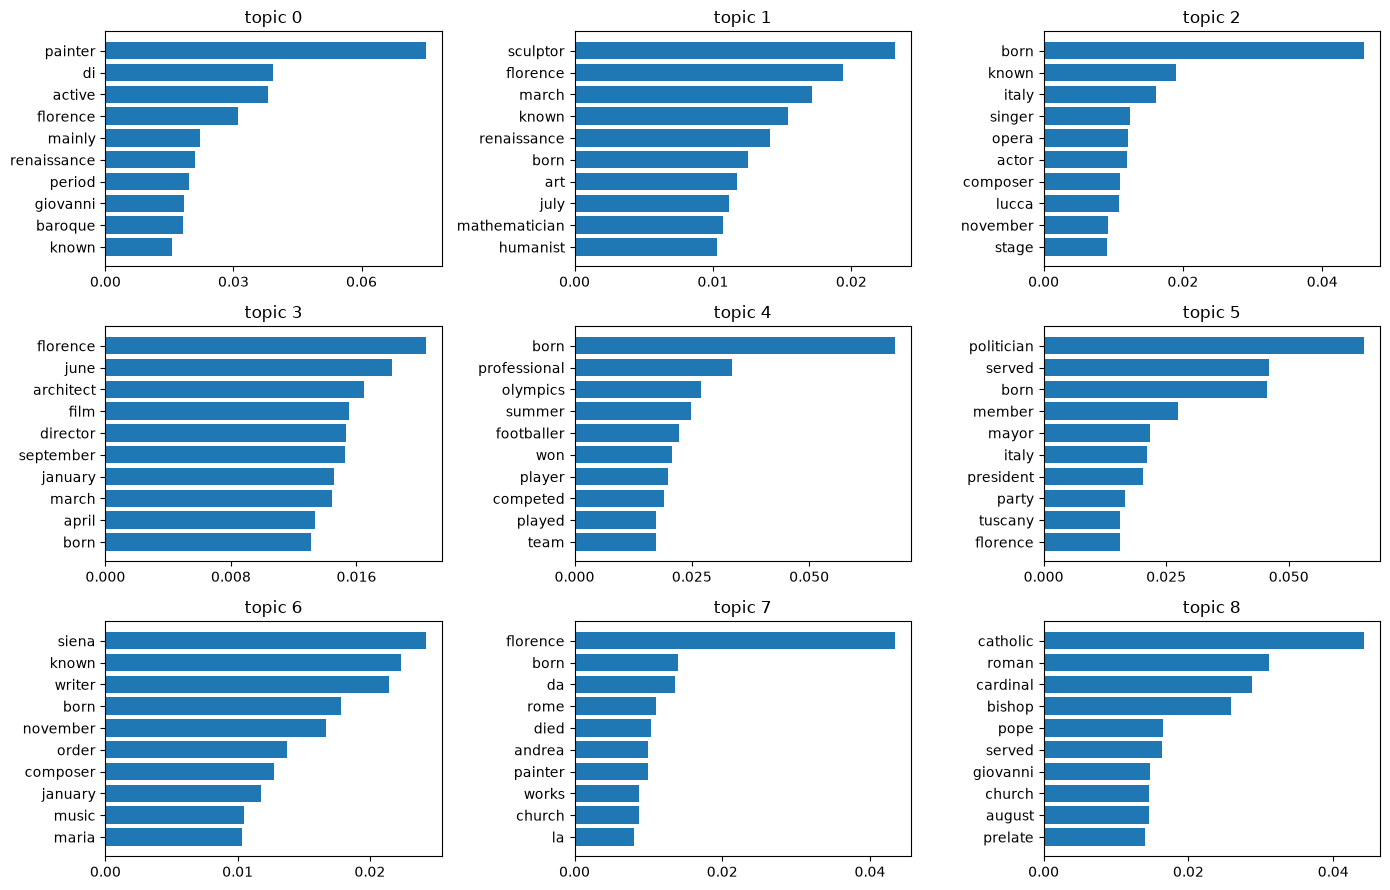

In [196]:
topic_word = lda.components_ / lda.components_.sum(axis=1, keepdims=True)   # each row: P(w | topic)

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for t, ax in enumerate(axes.ravel()):
    top = np.argsort(topic_word[t])[-10:]
    ax.barh(words[top], topic_word[t][top])
    ax.set_title(f"topic {t}")
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
plt.tight_layout()
plt.show()

Each paragraph is a **mixture** of topics. The mixtures of a few paragraphs:

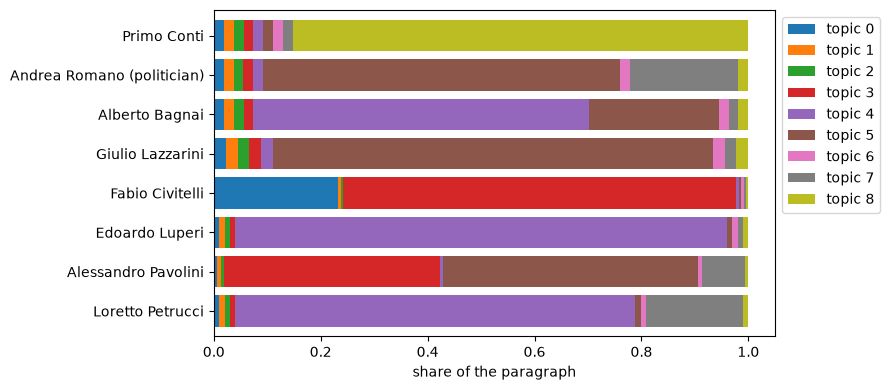

In [197]:
shown = np.random.default_rng(0).choice(len(explore), 8, replace=False)
mix = pd.DataFrame(doc_topic[shown], columns=[f"topic {t}" for t in range(9)],
                   index=explore["title"].to_numpy()[shown])
mix.plot.barh(stacked=True, figsize=(9, 4), width=0.8)
plt.xlabel("share of the paragraph"); plt.legend(bbox_to_anchor=(1, 1))
plt.gca().invert_yaxis(); plt.tight_layout()
plt.show()

Where does each share come from? LDA assigns every word of a paragraph to a topic: the probability that a word $w$
of paragraph $d$ comes from topic $t$ is proportional to the topic's share in the paragraph times the word's
probability in the topic, $\theta_{d,t} \cdot P(w \mid t)$. Each word below is coloured by its most likely topic,
with the colours of the bars. Uncoloured words are not in the LDA vocabulary: stopwords, dates, rare words.

In [198]:
import re, html
from IPython.display import HTML, display
from matplotlib.colors import to_hex

topic_colors = [to_hex(f"C{t}") for t in range(9)]          # the colours of the bar chart
word_index = count_vect.vocabulary_

def colored(text, theta):
    out, last = [], 0
    for m in re.finditer(WORDS_ONLY, text):
        out.append(html.escape(text[last:m.start()]))
        w = m.group().lower()
        if w in word_index:
            t = np.argmax(theta * topic_word[:, word_index[w]])   # most likely topic of this word, here
            c = topic_colors[t]
            out.append(f'<span style="background:{c}55; border-bottom:2px solid {c}" title="topic {t}">'
                       f'{html.escape(m.group())}</span>')
        else:
            out.append(html.escape(m.group()))
        last = m.end()
    return "".join(out) + html.escape(text[last:])

legend = " ".join(f'<span style="background:{c}55; border-bottom:2px solid {c}; padding:0 4px">topic {t}</span>'
                  for t, c in enumerate(topic_colors))
body = "".join(f"<p><b>{html.escape(explore['title'].iloc[i])}</b>: {colored(explore['text'].iloc[i], doc_topic[i])}</p>"
               for i in shown)
display(HTML(f"<div style='line-height:1.8'>{legend}{body}</div>"))

---
## Labels without annotators

Wikipedia's categories already describe each person's occupation (*Italian painters*, *Footballers from
Pisa*, *Roman Catholic bishops of Lucca*). We turn them into one of our nine domains with **rules**: a regular
expression per domain, matched against every category of the page. The domain with the most matching categories
wins; when two domains tie, the person is left unlabeled; when none matches, the label is *other*.

This is **distant supervision**: the labels come from metadata, not from someone reading the text.

In [202]:
import re

DOMAINS = {
    "visual arts": r"painter|sculptor|architect|artist|engraver|illustrator|photographer|designer|illuminator|printmaker|draughts|ceramist|goldsmith",
    "literature": r"writer|poet|novelist|dramatist|playwright|translator|journalist|essayist|librettist|historian|philosopher|philologist|critic|biographer|humanist",
    "music": r"musician|composer|singer|conductor|pianist|violinist|organist|tenor|soprano|baritone|guitarist|rapper",
    "film and stage": r"actor|actress|film director|comedian|television presenter|screenwriter|film producer|dancer",
    "science": r"scientist|physicist|mathematician|astronomer|engineer|medical doctor|physician|chemist|biologist|botanist|inventor|economist|geologist|zoologist|anatomist|psychologist|archaeologist",
    "politics": r"politician|deputies|deputy|senator|mayor|diplomat|minister|ambassador|jurist|lawyer|president|member of parliament|members of the|lords of|dukes of|grand dukes|rulers|heads of state|doges",
    "religion": r"bishop|cardinal|clergy|pope|priest|saint|monk|nun|jesuit|dominican|franciscan|friar|theologian|abbot|religious|beatified|venerated",
    "sport": r"sportspeople|sportsmen|sportswomen|footballer|cyclist|fencer|athlete|rugby|players|olympic|racing driver|swimmer|rower|boxer|basketball|volleyball|tennis|shooter|football manager|gymnast",
}
PATTERNS = {domain: re.compile(pattern, re.IGNORECASE) for domain, pattern in DOMAINS.items()}
LABELS = list(DOMAINS) + ["other"]

def silver_label(cats):
    votes = {d: sum(bool(p.search(c)) for c in cats) for d, p in PATTERNS.items()}
    best = max(votes.values())
    winners = [d for d, v in votes.items() if v == best]
    if best == 0:
        return "other"
    return winners[0] if len(winners) == 1 else None      # None: a tie, left unlabeled

people["silver"] = people["categories"].apply(silver_label)
people["silver"].value_counts(dropna=False)

silver
visual arts       801
sport             455
literature        301
politics          280
religion          227
music             123
other             110
film and stage    109
science           105
None               56
Name: count, dtype: int64

The classes are very **unbalanced**: a third of the people are artists (Florence again), fewer than 5% are
scientists. The rules are not perfect. Some people have categories of several domains:

In [203]:
for title in ["Francesco Furini", "Leonardo da Vinci"]:
    row = people[people.title == title].iloc[0]
    print(f"{title}: silver = {row.silver}\n  {row.text[:180]}\n")

Francesco Furini: silver = visual arts
  Francesco Furini ( 10 apr. 1603 – 19 August 1646) was an Italian Baroque painter, poet and priest.  He was a leading painter in Florence in the second quarter of the 17th century a

Leonardo da Vinci: silver = visual arts
  Leonardo di ser Piero da Vinci (15 April 1452 – 2 May 1519) was an Italian polymath of the High Renaissance who was active as a painter, draughtsman, engineer, scientist, theorist,



### Do clusters and topics match the silver labels?

Now that each training paragraph has a silver label, we can check whether the groups found without labels correspond to
the domains. The table shows, for each silver label, how its paragraphs are spread over the clusters (rows sum
to 1).

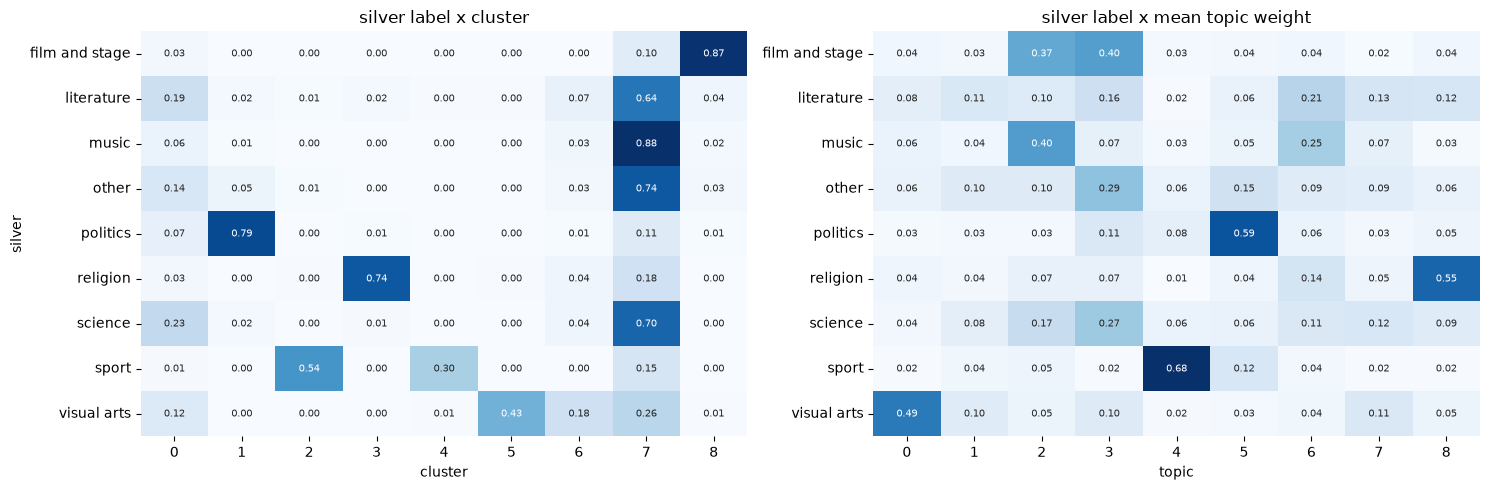

In [204]:
explore["silver"] = people.loc[explore.index, "silver"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(pd.crosstab(explore.silver, explore.cluster, normalize="index"), cmap="Blues", ax=axes[0], cbar=False, annot=True, fmt=".2f", annot_kws={"size": 7})
sns.heatmap(pd.DataFrame(doc_topic).groupby(explore.silver.to_numpy()).mean(), cmap="Blues", ax=axes[1], cbar=False, annot=True, fmt=".2f", annot_kws={"size": 7})
axes[0].set_title("silver label x cluster"); axes[1].set_title("silver label x mean topic weight")
axes[1].set_xlabel("topic")
plt.tight_layout()
plt.show()

Religion, politics, film and stage and sport each map mainly to one cluster (sport to two: football and the
Olympic sports), and visual arts to the painter clusters. Literature, music, science and *other* have no cluster of
their own, and spread over several, mostly the catch-all ones. The topics show the same picture, more blurred.

This anticipates the classifier: the domains that the clusters find without labels are the easy ones; those without
a cluster will be the hard ones.

The same t-SNE map, now coloured by silver label:

In [205]:
points["silver"] = explore["silver"].fillna("tie").to_numpy()
fig = px.scatter(points, x="tsne 1", y="tsne 2", color="silver", hover_data=["title", "paragraph"],
                 opacity=0.7, title="t-SNE, coloured by silver label", width=850, height=550)
fig.update_traces(marker_size=4)
fig.show()

And, for each silver label, the **dominant** topic of its paragraphs, in counts:

In [206]:
pd.crosstab(explore["silver"], explore["topic"], rownames=["silver"], colnames=["dominant topic"])

dominant topic,0,1,2,3,4,5,6,7,8
silver,,,,,,,,,
film and stage,2,1,45,46,0,1,1,0,2
literature,17,30,27,47,0,18,68,37,34
music,4,3,56,8,1,5,28,9,1
other,5,10,10,34,2,15,11,8,6
politics,3,4,4,25,7,191,10,3,11
religion,5,6,14,11,0,2,28,6,138
science,3,4,21,35,2,4,7,11,9
sport,0,15,13,1,344,43,3,1,1
visual arts,432,67,30,77,5,14,19,71,24


Three topics each collect most of one domain: sport (topic 4), politics (5) and religion (8), and most painters go
to topic 0. Music, film and stage share topics 2 and 3; literature and science spread over all of them. The
topics, like the clusters, find the domains with a distinctive vocabulary, and miss the others.

Both are labeled *visual arts*, which is reasonable here. But the rules only count categories: a person with
many categories in one domain wins over the occupation the text puts first. These are the errors that the gold
labels will reveal.

---
## Gold labels and agreement

To know how good the silver labels are, and to evaluate a model honestly, we need labels written by a
**person**, from the **text** alone. 200 paragraphs, sampled at random from the corpus, were annotated by hand
following written guidelines (`data/annotation_guidelines.md`). In short:

- label what the person is **mainly known for**, according to the paragraph only;
- with several occupations, the one presented as the main one, or else the **first** one listed;
- rulers with a political role are *politics*, nobility without one is *other*;
- when unsure, choose the most likely label and write a note.

In [207]:
gold = pd.read_csv("data/gold_annotations.csv", encoding="utf-8-sig")
gold["label"] = gold["label"].str.strip().str.lower()

assert gold["label"].notna().all(), "some rows have no label yet"
assert gold["label"].isin(LABELS).all(), f"unknown labels: {set(gold.label) - set(LABELS)}"

gold = gold.merge(people[["title", "categories", "silver"]], on="title", how="left")
gold["label"].value_counts()

label
visual arts       58
sport             33
politics          23
religion          21
film and stage    20
literature        19
science           11
other              8
music              7
Name: count, dtype: int64

### The rules as one more annotator

We treat the rules as a second annotator, and compare them with the human on the same 200 paragraphs.
Ties count as disagreements.

In [208]:
from sklearn.metrics import cohen_kappa_score

rules = gold["silver"].fillna("tie")
print(f"raw agreement: {(rules == gold.label).mean():.3f}")
print(f"Cohen's kappa: {cohen_kappa_score(gold.label, rules):.3f}")

pd.crosstab(gold.label, rules, rownames=["human"], colnames=["rules"])

raw agreement: 0.830
Cohen's kappa: 0.797


rules,film and stage,literature,music,other,politics,religion,science,sport,tie,visual arts
human,,,,,,,,,,
film and stage,11,1,0,1,2,0,0,0,3,2
literature,0,16,1,0,0,0,0,0,2,0
music,0,0,7,0,0,0,0,0,0,0
other,0,1,0,2,3,0,0,0,0,2
politics,0,2,0,1,17,1,1,1,0,0
religion,0,3,0,0,0,16,2,0,0,0
science,0,0,0,5,0,0,6,0,0,0
sport,0,0,0,0,0,0,0,33,0,0
visual arts,0,0,0,0,0,0,0,0,0,58


There is substantial agreement, at the
threshold often taken as reliable. Every painter and every athlete gets the same label from both. The
disagreements concentrate in a few cells:

- five of the eleven *scientists* are *other* for the rules: physicians and medical specialists, whose
  categories (*gastroenterologists*, *epidemiologists*) no pattern matches;
- *film and stage* is spread over five other labels, ties included: cinematographers and costume designers
  are not in the patterns;
- three *religion* people are *literature* for the rules: friars who also wrote.

In [209]:
disagree = gold[rules != gold.label]
for _, row in disagree.head(8).iterrows():
    print(f"human: {row.label:15s} rules: {str(row.silver):15s} | {row.text[:150]}")

human: science         rules: other           | Carlo Catassi (born 19 April 1953) is an Italian pediatric gastroenterologist and epidemiologist. He is a professor at the Università Politecnica dell
human: politics        rules: literature      | Marquis Gino Capponi (Florence, 13 September 1792 – Florence, 3 February 1876) was an Italian statesman and historian of a Liberal Catholic bent.
human: film and stage  rules: other           | Tonino Nardi (25 September 1939 – 24 October 1993) was an Italian film cinematographer.
human: religion        rules: literature      | Giovanni Antonio Bianchi (1686–1768) was an Italian Friar Minor, theologian, and minor Tuscan poet.
human: film and stage  rules: visual arts     | Maria De Matteis (6 March 1898 – 9 December 1988) was an Italian costume designer. Her accolades include a BAFTA Award, in addition to nominations for
human: religion        rules: literature      | Zanobi Acciaioli (25 May 1461 – 27 July 1519) was an Italian Dominican friar

Two kinds of disagreement:

- **missing vocabulary**: *gastroenterologist*, *cinematographer*, *physician* appear in categories that no
  pattern covers. The rules can be fixed.
- **different definitions**: Gino Capponi was a *statesman and historian*. The human follows the guidelines and
  takes the first occupation; the rules count categories, and he has more as a historian. Costanzo Ciano,
  *naval officer and politician*, is *other* for the human for the same reason.

And one case where the **guidelines** are wrong: Maria De Matteis, a costume designer, is *film and stage* for
the annotator, because her work is for films, while the guidelines put designers in *visual arts*. The
guidelines need a rule for her: this is the *revise* step of the annotation cycle.

---
## Training and evaluation

The design:

- **training set**: the corpus with its **silver** labels, minus the people with a tie, minus **all the gold
  people**: the test documents must never be seen in training;
- **test set**: the 200 **gold** paragraphs, used to evaluate, never to choose anything.

In [210]:
train = people[people.silver.notna() & ~people.title.isin(gold.title)]
x_train, y_train = train["text"].tolist(), train["silver"].to_numpy()
x_test, y_test = gold["text"].tolist(), gold["label"].to_numpy()

assert not set(train.title) & set(gold.title)
print(len(x_train), "training paragraphs (silver),", len(x_test), "test paragraphs (gold)")

2316 training paragraphs (silver), 200 test paragraphs (gold)


film and stage: 0.04
literature: 0.12
music: 0.05
other: 0.04
politics: 0.11
religion: 0.09
science: 0.04
sport: 0.18
visual arts: 0.32


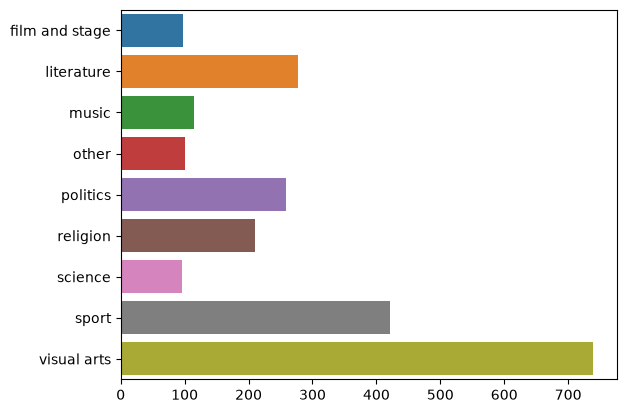

In [211]:
import seaborn as sns
import matplotlib.pyplot as plt

labels, counts = np.unique(y_train, return_counts=True)
for i, (label, count) in enumerate(zip(labels, counts)):
    print(label + ": " + str(round(count / y_train.shape[0], 2)))
df_counts = pd.DataFrame(counts[None, :], columns=labels)
sns.barplot(df_counts, orient="h")
plt.show()

### Baseline and a first model

The baseline always predicts the most frequent class. The model is the usual TF-IDF + logistic regression,
in a `Pipeline` so that the vectorizer only ever sees training texts.

In [212]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred), "macro-F1": f1_score(y_true, y_pred, average="macro")}

dummy = DummyClassifier(strategy="most_frequent").fit(x_train, y_train)
model = Pipeline([
    ("vect", TfidfVectorizer(min_df=2)),
    ("clf", LogisticRegression(max_iter=1000)),
]).fit(x_train, y_train)

pd.DataFrame({"majority class": scores(y_test, dummy.predict(x_test)),
              "TF-IDF + LR": scores(y_test, model.predict(x_test))}).T.round(3)

,accuracy,macro-F1
majority class,0.290,0.050
TF-IDF + LR,0.785,0.643


The majority class (*visual arts*) is right 29% of the time, with a macro-F1 of 0.05. The model reaches 0.79
accuracy, but only 0.64 macro-F1: the small classes do much worse than the large ones.

The majority class is not the only trivial baseline: a classifier can also guess at random, uniformly or
following the class proportions of the training set.

In [213]:
pd.DataFrame({strategy: scores(y_test, DummyClassifier(strategy=strategy, random_state=0)
                                .fit(x_train, y_train).predict(x_test))
              for strategy in ["most_frequent", "stratified", "uniform"]}).T.round(3)

,accuracy,macro-F1
most_frequent,0.290,0.050
stratified,0.145,0.101
uniform,0.125,0.119


Guessing at random gets a higher macro-F1 than the majority class (0.10 and 0.12 against 0.05), because it sometimes
predicts the small classes, but a much lower accuracy. A model has to beat all three.

### Silver scores are not gold scores

What if we had evaluated with cross-validation on the silver labels, as if they were the truth?

In [214]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
silver_cv = cross_val_score(model, x_train, y_train, cv=cv, scoring="f1_macro")

print(f"macro-F1, cross-validated on silver labels: {silver_cv.mean():.3f} +/- {silver_cv.std():.3f}")
print(f"macro-F1, on the gold test set: {f1_score(y_test, model.predict(x_test), average='macro'):.3f}")

macro-F1, cross-validated on silver labels: 0.689 +/- 0.016
macro-F1, on the gold test set: 0.643


The silver score measures how well the model **imitates the rules**; the gold score measures how often it is
right according to a person reading the text. Only the second one answers our question.

### Per class

With unbalanced classes, the average hides the small ones:

In [215]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred = model.predict(x_test)
print(classification_report(y_test, pred, labels=LABELS, zero_division=0, digits=3))

                precision    recall  f1-score   support

   visual arts      0.740     0.983     0.844        58
    literature      0.594     1.000     0.745        19
         music      1.000     1.000     1.000         7
film and stage      1.000     0.600     0.750        20
       science      0.000     0.000     0.000        11
      politics      0.824     0.609     0.700        23
      religion      0.889     0.762     0.821        21
         sport      0.889     0.970     0.928        33
         other      0.000     0.000     0.000         8

      accuracy                          0.785       200
     macro avg      0.659     0.658     0.643       200
  weighted avg      0.741     0.785     0.745       200



The last three lines of the report average the per-class scores in three ways:

- **macro avg**: the plain mean over classes, so every class counts the same, however small;
- **weighted avg**: the mean weighted by the number of test paragraphs of each class (the *support*);
- **accuracy**: the **micro** average. It pools the counts of all classes before computing precision and recall,
  and in single-label classification all three micro scores are equal to the accuracy.

On unbalanced data, macro-F1 is the honest summary: the weighted average is dominated by the large classes.

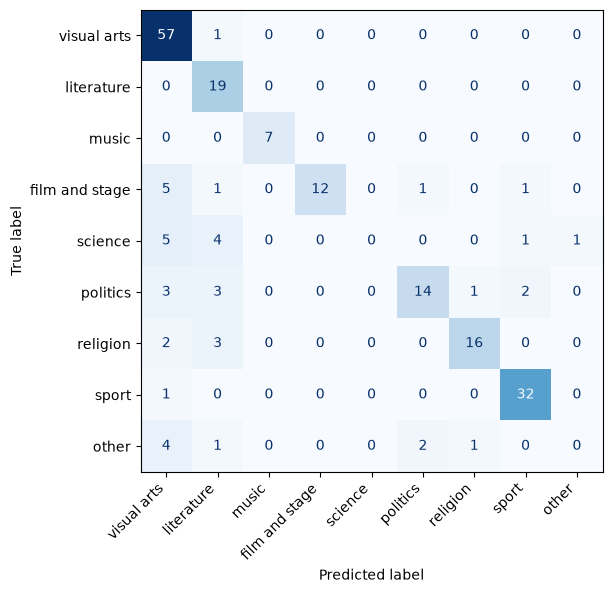

In [216]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, cmap="Blues",
                                        colorbar=False, ax=ax)
plt.xticks(rotation=45, ha="right")
plt.show()

Some classes have fewer than ten gold examples: one more mistake on them moves their F1 by several points. A
small gold set gives **uncertain** per-class scores.

Two classes score zero:

- *other* collects leftovers (bankers, generals, nobility) with nothing in common to learn;
- *science* is the smallest class in the training set (96 paragraphs), and the rules sent part of the
  scientists to *other*: the model never predicts *science*, and labels the eleven gold scientists as
  *literature* or *visual arts* instead.

*Literature* has the opposite problem: perfect recall, but four of its predictions out of ten are wrong. It is
where uncertain paragraphs end up.

### A rare class: is this person a scientist?

Most text classification problems look like this: one class of interest, few positives, many negatives. We turn
the task into a binary one, **science** against everything else: 4% of the training paragraphs, 11 of the 200
gold ones.

In [217]:
from sklearn.metrics import precision_score, recall_score

POSITIVE = "science"
yb_train = (y_train == POSITIVE).astype(int)
yb_test = (y_test == POSITIVE).astype(int)

binary = Pipeline([("vect", TfidfVectorizer(min_df=2)),
                   ("clf", LogisticRegression(max_iter=1000))]).fit(x_train, yb_train)
pred_b = binary.predict(x_test)

print(f"accuracy {accuracy_score(yb_test, pred_b):.3f}   precision {precision_score(yb_test, pred_b, zero_division=0):.3f}"
      f"   recall {recall_score(yb_test, pred_b):.3f}   F1 {f1_score(yb_test, pred_b):.3f}")
print(f"always answering 'not science': accuracy {1 - yb_test.mean():.3f}")

accuracy 0.945   precision 0.000   recall 0.000   F1 0.000
always answering 'not science': accuracy 0.945


The model never predicts *science*: its accuracy, 94.5%, is exactly that of always answering *not science*, and its
recall is 0. Accuracy does not see the problem.

### Moving the threshold

`predict` says *science* when the predicted probability is at least 0.5. With so few positives, the model is
rarely that confident. The threshold is a choice: lowering it trades precision for recall.

In [219]:
proba = binary.predict_proba(x_test)[:, 1]  # probability of science

pd.DataFrame([{"threshold": t, "predicted positive": int((proba >= t).sum()),
               "precision": precision_score(yb_test, proba >= t, zero_division=0),
               "recall": recall_score(yb_test, proba >= t),
               "F1": f1_score(yb_test, proba >= t)}
              for t in [0.5, 0.3, 0.2, 0.1, 0.05]]).round(3)

,threshold,predicted positive,precision,recall,F1
0,0.50,0,0.000,0.000,0.000
1,0.30,0,0.000,0.000,0.000
2,0.20,0,0.000,0.000,0.000
3,0.10,5,0.800,0.364,0.500
4,0.05,41,0.268,1.000,0.423


No paragraph reaches a probability of 0.2. At 0.1 the model finds 4 of the 11 scientists, and 4 of its 5
predictions are right; at 0.05 it finds all 11, but with 41 predictions.

Note that we just chose a threshold by looking at the test set. In a real experiment the threshold is a
hyperparameter, chosen on validation data.

### ROC and precision-recall curves

Both curves sweep **every** threshold:

- the **ROC** curve plots the recall (true positive rate) against the false positive rate, $FP / (FP + TN)$;
- the **precision-recall** curve plots precision against recall, and ignores the true negatives. Its area is the
  **average precision** (AP), whose random baseline is the share of positives, not 0.5.

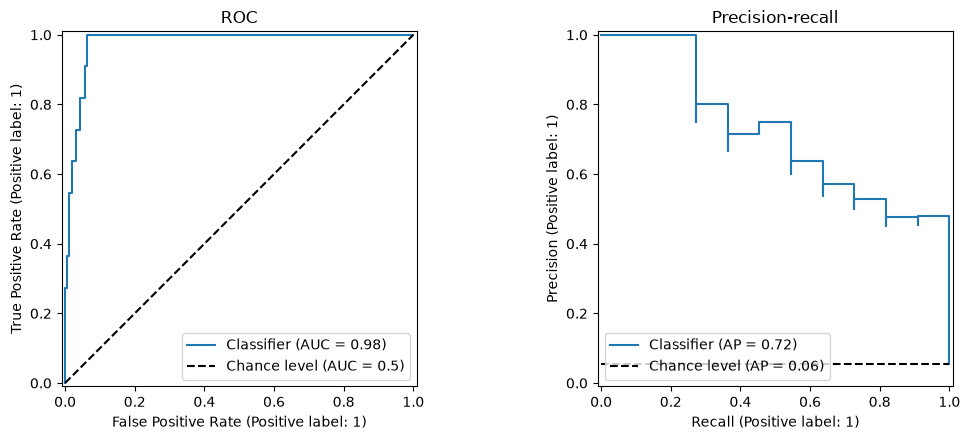

ROC-AUC: 0.978   (random: 0.5)
AP:      0.723   (random: 0.055)


In [ ]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, roc_auc_score, average_precision_score

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(yb_test, proba, ax=axes[0], plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(yb_test, proba, ax=axes[1], plot_chance_level=True)
axes[0].set_title("ROC"); axes[1].set_title("Precision-recall")
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc_score(yb_test, proba):.3f}   (random: 0.5)")  # macro by default
print(f"AP: {average_precision_score(yb_test, proba):.3f}   (random: {yb_test.mean():.3f})")

ROC-AUC is 0.98: the model ranks almost every scientist above almost every other person. AP is 0.72: on the
precision-recall curve, the few non-scientists ranked near the top cost a lot, because there are only 11
positives, while ROC divides them by the 189 negatives. On rare classes, report AP next to ROC-AUC.

With 11 positives, both numbers are uncertain: one scientist more or less moves them by several points.

### Reweighting the classes

Instead of moving the threshold after training, we can make the mistakes on the rare class cost more **during**
training: `class_weight="balanced"` weighs the loss of each paragraph by the inverse frequency of its class.

In [222]:
weighted = Pipeline([("vect", TfidfVectorizer(min_df=2)),
                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(x_train, yb_train)
p = weighted.predict(x_test)
print(f"precision {precision_score(yb_test, p, zero_division=0):.3f}   recall {recall_score(yb_test, p):.3f}   F1 {f1_score(yb_test, p):.3f}")

precision 0.800   recall 0.364   F1 0.500


F1 goes from 0 to 0.50 at the default threshold, the same trade-off we obtained by lowering the threshold to 0.1:
one acts during training, the other after.

### Choosing the hyperparameters

We tune the model with cross-validation on the **training** set only, scoring with macro-F1: the regularization
strength `C`, whether to reweight the classes, and whether to use word pairs (bigrams) too.

In [223]:
from sklearn.model_selection import GridSearchCV

grid = {
    "vect__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [1, 10, 100],
    "clf__class_weight": [None, "balanced"],
}
search = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(x_train, y_train)

print("best:", search.best_params_)
print(f"cross-validated macro-F1 (silver): {search.best_score_:.3f}")

best: {'clf__C': 10, 'clf__class_weight': 'balanced', 'vect__ngram_range': (1, 1)}
cross-validated macro-F1 (silver): 0.827


In [224]:
pd.DataFrame(search.cv_results_).head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__C,param_clf__class_weight,param_vect__ngram_range,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.248024,0.019793,0.009986,0.001013,1,None,"(1, 1)","{'clf__C': 1, 'clf__class_weight': None, 'vect...",0.667208,0.688158,0.709405,0.702118,0.675912,0.688560,0.015712,11
1,0.482149,0.016818,0.026397,0.011287,1,None,"(1, 2)","{'clf__C': 1, 'clf__class_weight': None, 'vect...",0.650094,0.686833,0.665848,0.684784,0.654515,0.668415,0.015117,12
2,0.183394,0.012111,0.013581,0.003349,1,balanced,"(1, 1)","{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.810378,0.846012,0.819105,0.824174,0.830312,0.825996,0.011950,3
3,0.384521,0.057786,0.023739,0.003477,1,balanced,"(1, 2)","{'clf__C': 1, 'clf__class_weight': 'balanced',...",0.804722,0.827220,0.821258,0.823372,0.827249,0.820764,0.008344,6
4,0.291134,0.033031,0.012009,0.004841,10,None,"(1, 1)","{'clf__C': 10, 'clf__class_weight': None, 'vec...",0.772442,0.821116,0.819390,0.831922,0.800728,0.809120,0.020905,9


And, once, on the gold test set:

In [47]:
pd.DataFrame({"first model": scores(y_test, model.predict(x_test)),
              "tuned model": scores(y_test, search.predict(x_test))}).T.round(3)

,accuracy,macro-F1
first model,0.785,0.643
tuned model,0.840,0.746


Accuracy goes from 0.79 to 0.84, and macro-F1 from 0.64 to 0.75. Most of the gain comes from
`class_weight="balanced"`: the model now predicts *science* (6 of 11 found, F1 from 0 to 0.67). *Other* is still
at zero.

The cross-validated silver score (0.83) is eight points above the gold one: the gap between imitating the rules
and being right has not closed.

### What did the model learn?

The words with the largest weight for each class:

In [48]:
best = search.best_estimator_
vocab = best.named_steps["vect"].get_feature_names_out()
clf = best.named_steps["clf"]

for c, name in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[c])[-8:][::-1]
    print(f"{name:15s}", ", ".join(vocab[top]))

film and stage  actor, actress, film, director, television, screenwriter, stage, dancer
literature      writer, poet, historian, author, philologist, journalist, philosopher, and
music           composer, singer, pianist, music, tenor, conductor, operatic, opera
other           banker, wife, general, anarchist, ii, commander, between, communist
politics        politician, served, mayor, of, party, diplomat, minister, member
religion        catholic, cardinal, bishop, archbishop, roman, rabbi, prelate, dominican
science         mathematician, physicist, engineer, botanist, psychiatrist, archaeologist, physician, university
sport           professional, player, footballer, olympics, former, is, competed, cyclist
visual arts     painter, architect, sculptor, artist, designer, active, photographer, baroque


The weights are occupation words: the model has learned the vocabulary the rules were built on, reading it in
the text instead of the categories. A few are not occupations: *is* for sport, because most athletes are alive,
and their biographies are written in the present tense; *wife* and *ii* for *other*, where the noble families
end up.

---
## Comparing models

### Feature selection inside the search

A $\chi^2$ filter scores every word against the classes, and `SelectKBest` keeps the best $k$. How many words to
keep is one more hyperparameter, so it goes inside the pipeline and the search: the filter is then fit on the
training folds only.

In [49]:
from sklearn.feature_selection import SelectKBest, chi2

select_search = GridSearchCV(
    Pipeline([("vect", TfidfVectorizer(min_df=2)),
              ("select", SelectKBest(chi2)),
              ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    {"select__k": [100, 300, 1000, "all"], "clf__C": [10, 100]},
    cv=cv, scoring="f1_macro", n_jobs=-1).fit(x_train, y_train)

print("vocabulary size:", len(select_search.best_estimator_.named_steps["vect"].vocabulary_))
print("best:", select_search.best_params_)
print(f"cross-validated macro-F1 (silver): {select_search.best_score_:.3f}")
pd.DataFrame(select_search.cv_results_).pivot_table(index="param_clf__C", columns="param_select__k",
                                                    values="mean_test_score").round(3)

vocabulary size: 4602
best: {'clf__C': 10, 'select__k': 300}
cross-validated macro-F1 (silver): 0.834


param_select__k,100,300,1000,all
param_clf__C,,,,
10,0.777,0.834,0.831,0.827
100,0.774,0.826,0.823,0.825


Keeping 300 of the 4,602 words is the best choice, slightly better than keeping all of them (0.834 against 0.827), a
difference within the spread across folds. 100 words are too few.

### Competitors

Is logistic regression the right model? We compare it with two others, tuned on the same folds with the same
metric:

- **Naive Bayes** on word counts, with one smoothing parameter $\alpha$: a small grid is enough;
- a **random forest**, with many hyperparameters and many possible values: instead of a full grid, we try a fixed
  number of **random** combinations with `RandomizedSearchCV`.

In [50]:
from sklearn.naive_bayes import MultinomialNB

nb_search = GridSearchCV(
    Pipeline([("vect", CountVectorizer(min_df=2)), ("clf", MultinomialNB())]),
    {"clf__alpha": [0.01, 0.1, 0.5, 1.0]},
    cv=cv, scoring="f1_macro", n_jobs=-1).fit(x_train, y_train)

print("best:", nb_search.best_params_)
print(f"cross-validated macro-F1 (silver): {nb_search.best_score_:.3f}")

best: {'clf__alpha': 0.1}
cross-validated macro-F1 (silver): 0.756


In [51]:
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_search = RandomizedSearchCV(
    Pipeline([("vect", TfidfVectorizer(min_df=2)), ("clf", RandomForestClassifier(random_state=0))]),
    {"clf__n_estimators": randint(100, 400),             # any integer in [100, 400)
     "clf__max_features": ["sqrt", "log2"],
     "clf__min_samples_leaf": randint(1, 5),
     "clf__class_weight": [None, "balanced", "balanced_subsample"]},
    n_iter=10, cv=cv, scoring="f1_macro", n_jobs=-1, random_state=0).fit(x_train, y_train)

print("best:", rf_search.best_params_)
print(f"cross-validated macro-F1 (silver): {rf_search.best_score_:.3f}")

best: {'clf__class_weight': 'balanced', 'clf__max_features': 'log2', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 342}
cross-validated macro-F1 (silver): 0.811


The models, by **cross-validated** macro-F1 on the training set. This is the comparison we choose on; the test
set plays no part in it.

In [52]:
pd.Series({"Naive Bayes": nb_search.best_score_,
           "logistic regression": search.best_score_,
           "logistic regression + chi2": select_search.best_score_,
           "random forest": rf_search.best_score_}, name="cv macro-F1 (silver)").round(3).to_frame()

,cv macro-F1 (silver)
Naive Bayes,0.756
logistic regression,0.827
logistic regression + chi2,0.834
random forest,0.811


Naive Bayes is far behind. The other three are within two points, about the spread across folds: logistic
regression with $\chi^2$ is first, but the evidence is thin. When models are this close, prefer the simpler one:
the logistic regression, fast to train and readable.

### Weights and importances

The logistic regression has one weight vector per class, so we can read which words push a paragraph towards
each domain:

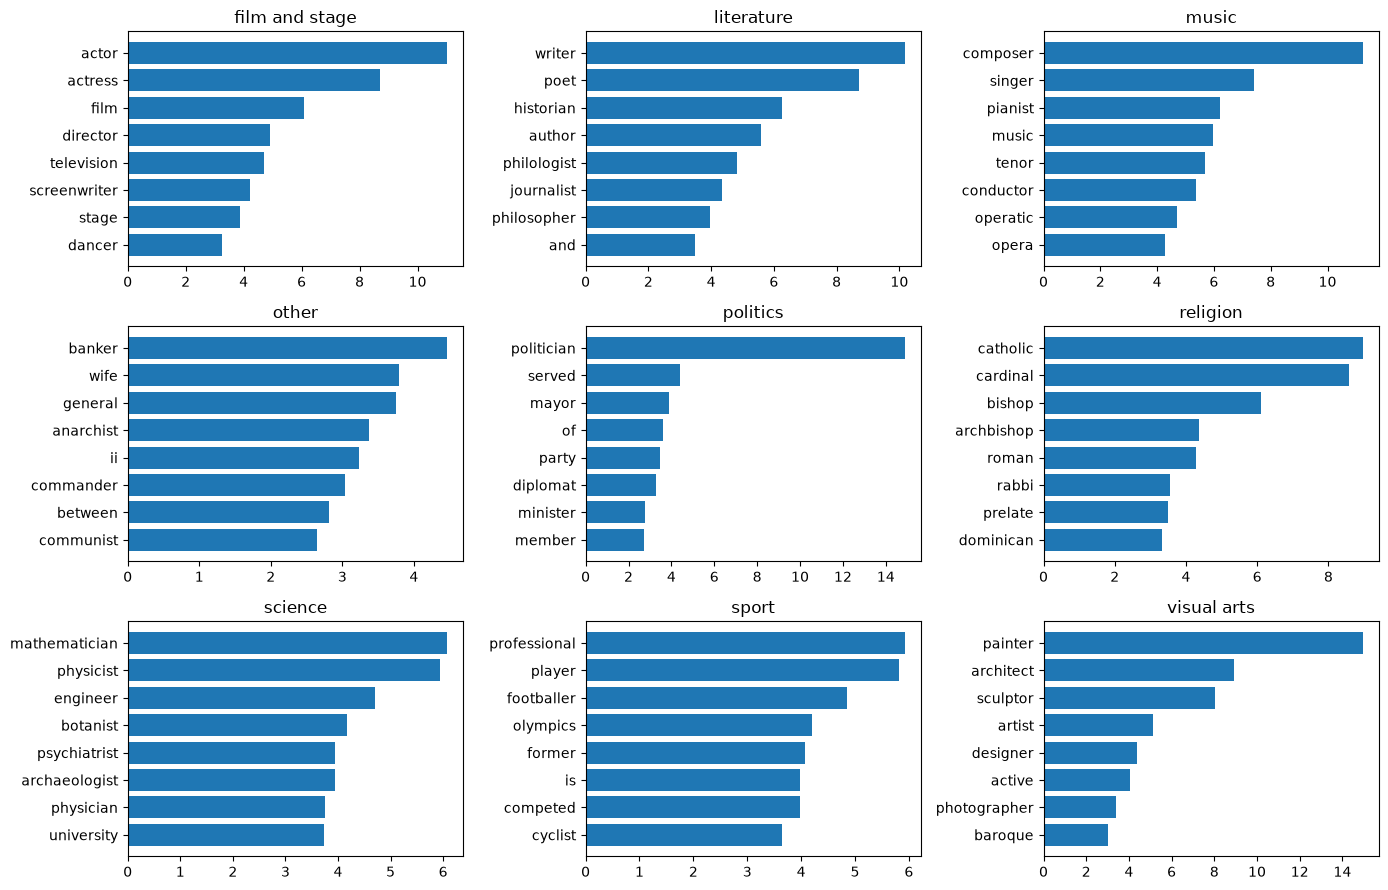

In [53]:
lr_best = search.best_estimator_
lr_vocab = lr_best.named_steps["vect"].get_feature_names_out()
lr = lr_best.named_steps["clf"]

fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for c, ax in enumerate(axes.ravel()):
    top = np.argsort(lr.coef_[c])[-8:]
    ax.barh(lr_vocab[top], lr.coef_[c][top])
    ax.set_title(lr.classes_[c])
plt.tight_layout()
plt.show()

A forest has no weights per class. Its **impurity importance** measures how much each word contributed to the
splits, over all trees and all classes:

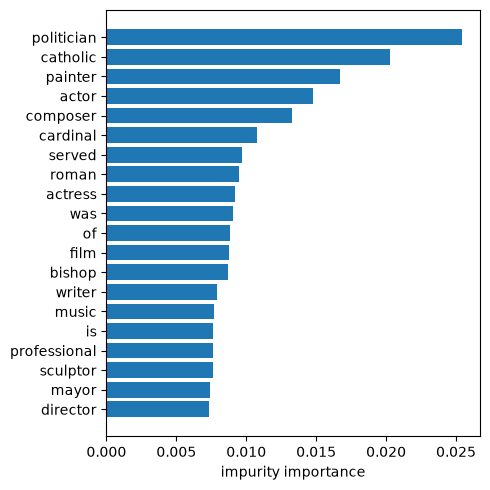

In [54]:
rf_best = rf_search.best_estimator_
rf_vocab = rf_best.named_steps["vect"].get_feature_names_out()
importance = rf_best.named_steps["clf"].feature_importances_

top = np.argsort(importance)[-20:]
plt.figure(figsize=(5, 5))
plt.barh(rf_vocab[top], importance[top])
plt.xlabel("impurity importance")
plt.tight_layout()
plt.show()

The most important words are again occupation words. Unlike the weights of the logistic regression, importances
have no sign and no class: a word can be important because it rules a class in, or out.

### The test scores, for the report

The choice was made on the training data. For the report, the gold test scores of every model:

In [55]:
pd.DataFrame({name: scores(y_test, m.predict(x_test))
              for name, m in [("majority class", dummy), ("Naive Bayes", nb_search),
                              ("logistic regression", search), ("logistic regression + chi2", select_search),
                              ("random forest", rf_search)]}).T.round(3)

,accuracy,macro-F1
majority class,0.290,0.050
Naive Bayes,0.795,0.695
logistic regression,0.840,0.746
logistic regression + chi2,0.820,0.754
random forest,0.840,0.751


On the gold test set the order changes: the random forest ties with logistic regression on accuracy, and
$\chi^2$ selection has the best macro-F1, by less than one point. On 200 paragraphs, differences of this size are
noise. The choice made with cross-validation stands; the test scores are reported, not used to choose.

---
## Exercises

- **Your own agreement.** With a classmate, label the first 30 rows of `data/gold_annotations.csv` separately,
  following the guidelines, without looking at the `label` column. Compute Cohen's kappa between the two of you,
  and between each of you and the gold labels. Discuss the disagreements: which guideline would you change?
- **How much silver data is needed?** Train the tuned pipeline on 10%, 25%, 50% and 100% of the training set
  (stratified samples) and plot the gold macro-F1 against the size.
- **Gold only.** Ignore the silver labels: evaluate the same pipeline with cross-validation on the 200 gold
  paragraphs alone. How does the score compare, and how large is the spread across folds?
- **Better rules.** Look at the disagreements between rules and human. Change `DOMAINS` (or the way ties are
  handled), and check that the agreement with the gold labels improves. Does the model trained on the new silver
  labels improve too?
- **Scrape another region.** Using `api_pages` and the category structure, collect the people from another
  Italian region, apply the rules, and evaluate the model trained on Tuscany on them. What changes?